# Chart Selection: Examples and Decision Practice

This notebook demonstrates how different analytical questions lead to different chart choices. All data is generated locally.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(24)
print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Create sample business data

In [2]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
business = pd.DataFrame({
    "month": months,
    "revenue": [120, 135, 128, 160, 172, 185],
    "orders": [12, 14, 13, 16, 18, 20],
    "ad_spend": [10, 12, 11, 15, 17, 19],
    "web_revenue": [70, 82, 78, 100, 108, 120],
    "store_revenue": [50, 53, 50, 60, 64, 65]
})
business

,month,revenue,orders,ad_spend,web_revenue,store_revenue
0,Jan,120,12,10,70,50
1,Feb,135,14,12,82,53
2,Mar,128,13,11,78,50
3,Apr,160,16,15,100,60
4,May,172,18,17,108,64
5,Jun,185,20,19,120,65


## 2. Goal: compare categories → bar chart

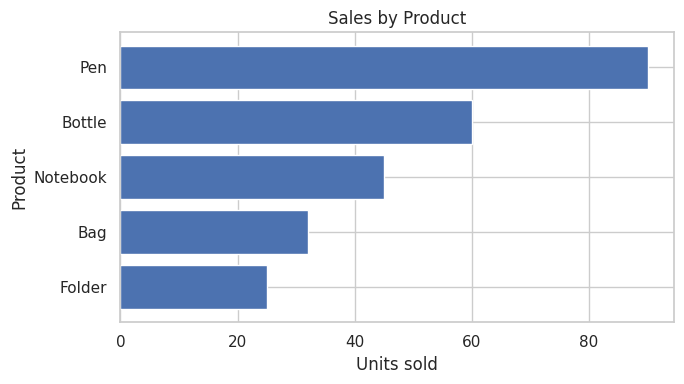

In [3]:
products = pd.DataFrame({
    "product": ["Notebook", "Pen", "Bag", "Bottle", "Folder"],
    "sales": [45, 90, 32, 60, 25]
}).sort_values("sales", ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(products["product"], products["sales"])
ax.set(title="Sales by Product", xlabel="Units sold", ylabel="Product")
fig.tight_layout()
plt.show()

## 3. Goal: show change over time → line chart

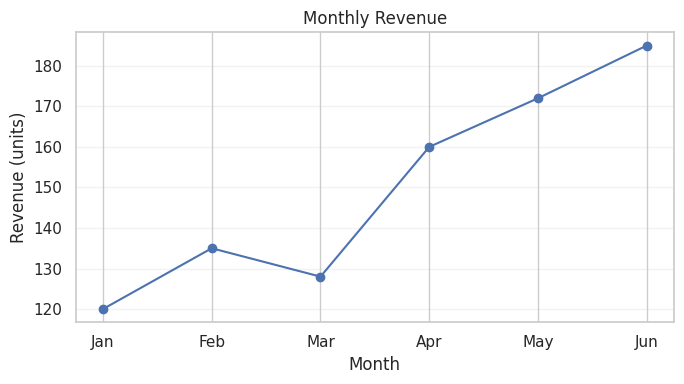

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(business["month"], business["revenue"], marker="o")
ax.set(title="Monthly Revenue", xlabel="Month", ylabel="Revenue (units)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 4. Goal: understand a distribution → histogram and ECDF

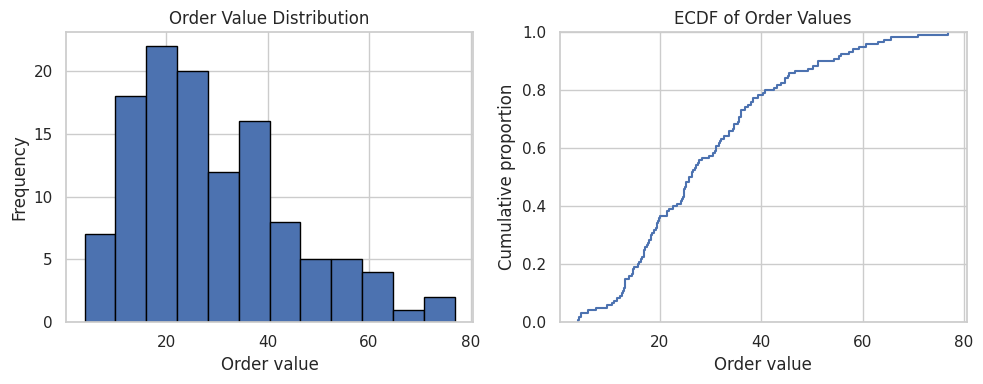

In [5]:
order_values = rng.gamma(shape=4.0, scale=8.0, size=120)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(order_values, bins=12, edgecolor="black")
axes[0].set(title="Order Value Distribution", xlabel="Order value", ylabel="Frequency")
sns.ecdfplot(x=order_values, ax=axes[1])
axes[1].set(title="ECDF of Order Values", xlabel="Order value", ylabel="Cumulative proportion")
fig.tight_layout()
plt.show()

## 5. Goal: compare group distributions → box plot

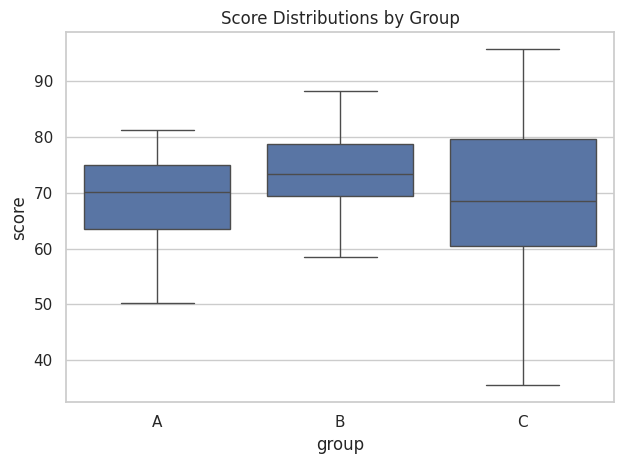

In [6]:
scores = pd.DataFrame({
    "group": np.repeat(["A", "B", "C"], 40),
    "score": np.concatenate([
        rng.normal(68, 8, 40),
        rng.normal(74, 7, 40),
        rng.normal(71, 12, 40)
    ]).clip(0, 100)
})
sns.boxplot(data=scores, x="group", y="score")
plt.title("Score Distributions by Group")
plt.tight_layout()
plt.show()

## 6. Goal: inspect a relationship → scatter plot

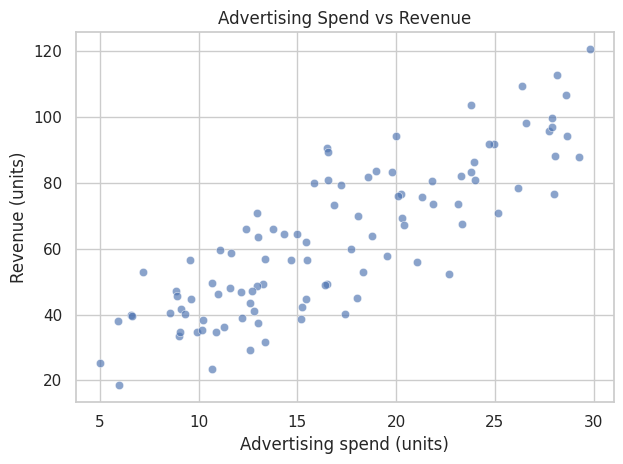

In [7]:
ad_spend = rng.uniform(5, 30, 100)
revenue = 15 + 2.8 * ad_spend + rng.normal(0, 12, 100)
relationship = pd.DataFrame({"ad_spend": ad_spend, "revenue": revenue})
sns.scatterplot(data=relationship, x="ad_spend", y="revenue", alpha=0.65)
plt.title("Advertising Spend vs Revenue")
plt.xlabel("Advertising spend (units)")
plt.ylabel("Revenue (units)")
plt.tight_layout()
plt.show()

## 7. Goal: compare composition → stacked bar chart

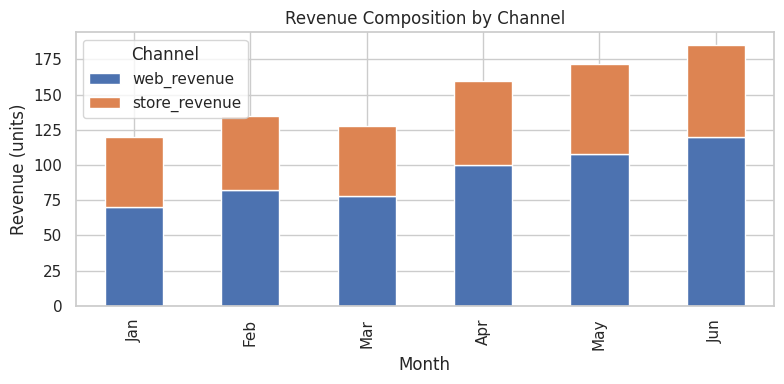

In [8]:
composition = business.set_index("month")[["web_revenue", "store_revenue"]]
composition.plot(kind="bar", stacked=True, figsize=(8, 4))
plt.title("Revenue Composition by Channel")
plt.xlabel("Month")
plt.ylabel("Revenue (units)")
plt.legend(title="Channel")
plt.tight_layout()
plt.show()

## 8. Goal: compare correlations → heatmap

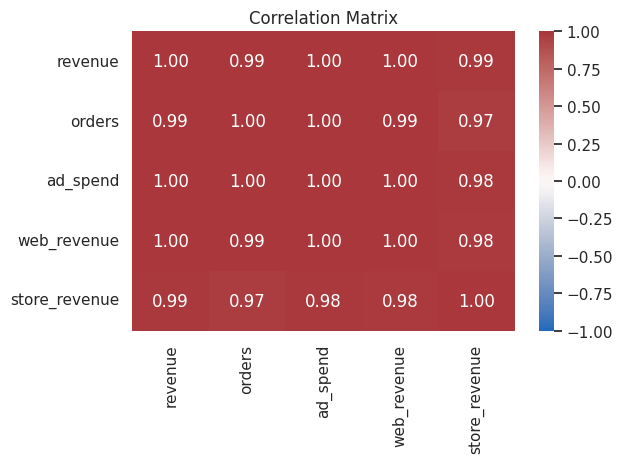

In [9]:
numeric = business[["revenue", "orders", "ad_spend", "web_revenue", "store_revenue"]]
corr = numeric.corr()
sns.heatmap(corr, annot=True, vmin=-1, vmax=1, cmap="vlag", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## 9. Decision practice

For each question, write the chart you would choose and why:

1. Which five products have the highest sales?
2. Did revenue increase over the last 12 months?
3. Are delivery times skewed?
4. Do delivery times differ across shipping types?
5. Are advertising spend and revenue associated?
6. What percentage of orders came from each channel each month?

For each choice, mention one limitation or design check.

## 10. Final checklist

- What question does the chart answer?
- Are variable types and ordering appropriate?
- Are scales, units, and denominators clear?
- Is the chart readable and accessible?
- Does the interpretation avoid unsupported causal claims?